CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/TV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/PM_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/TV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/PM_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//sum_plots/RV_septum

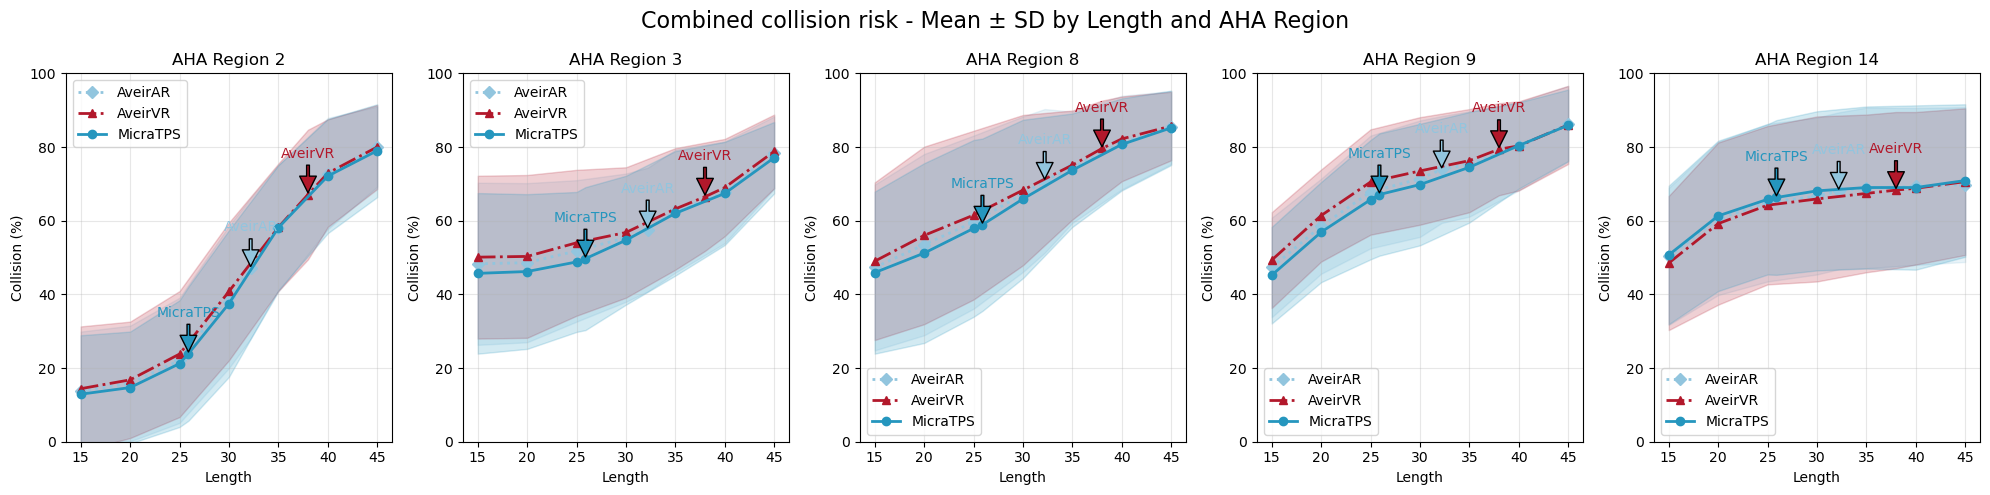

Axes(0.125,0.11;0.133621x0.77)


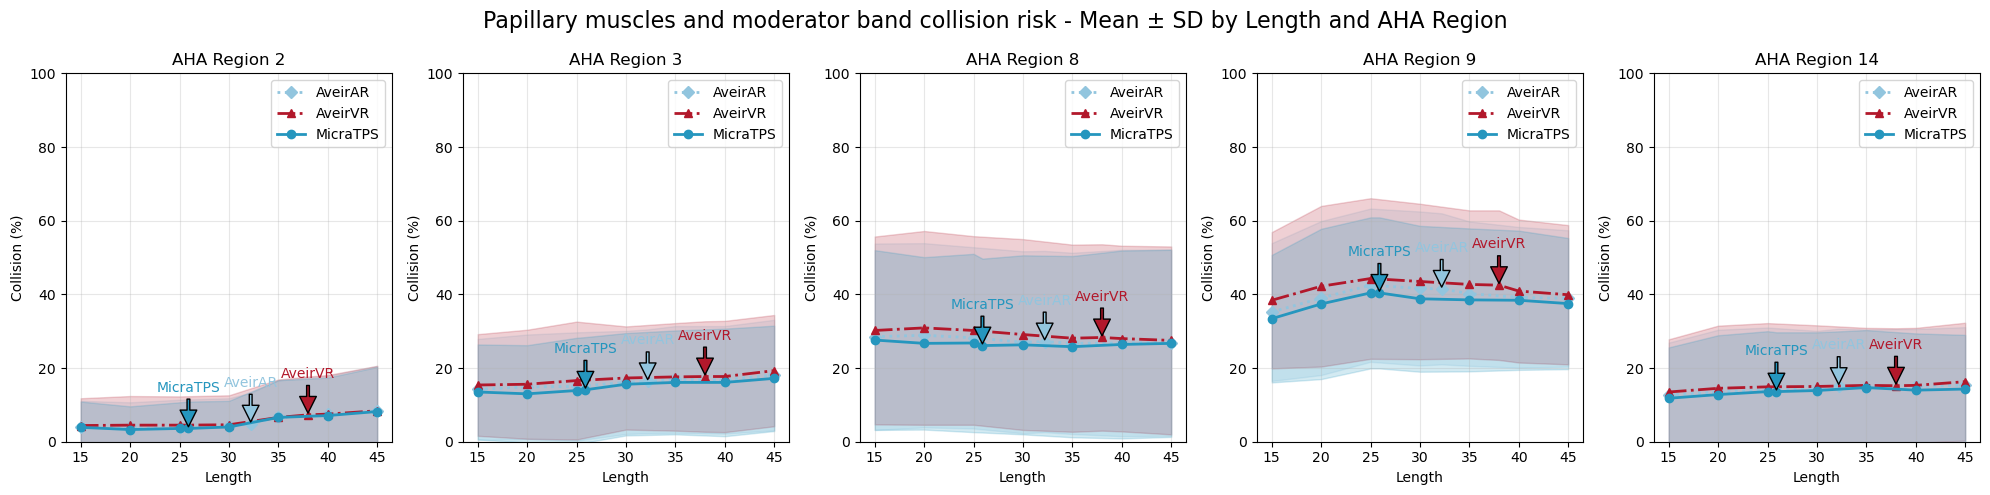

Axes(0.125,0.11;0.133621x0.77)


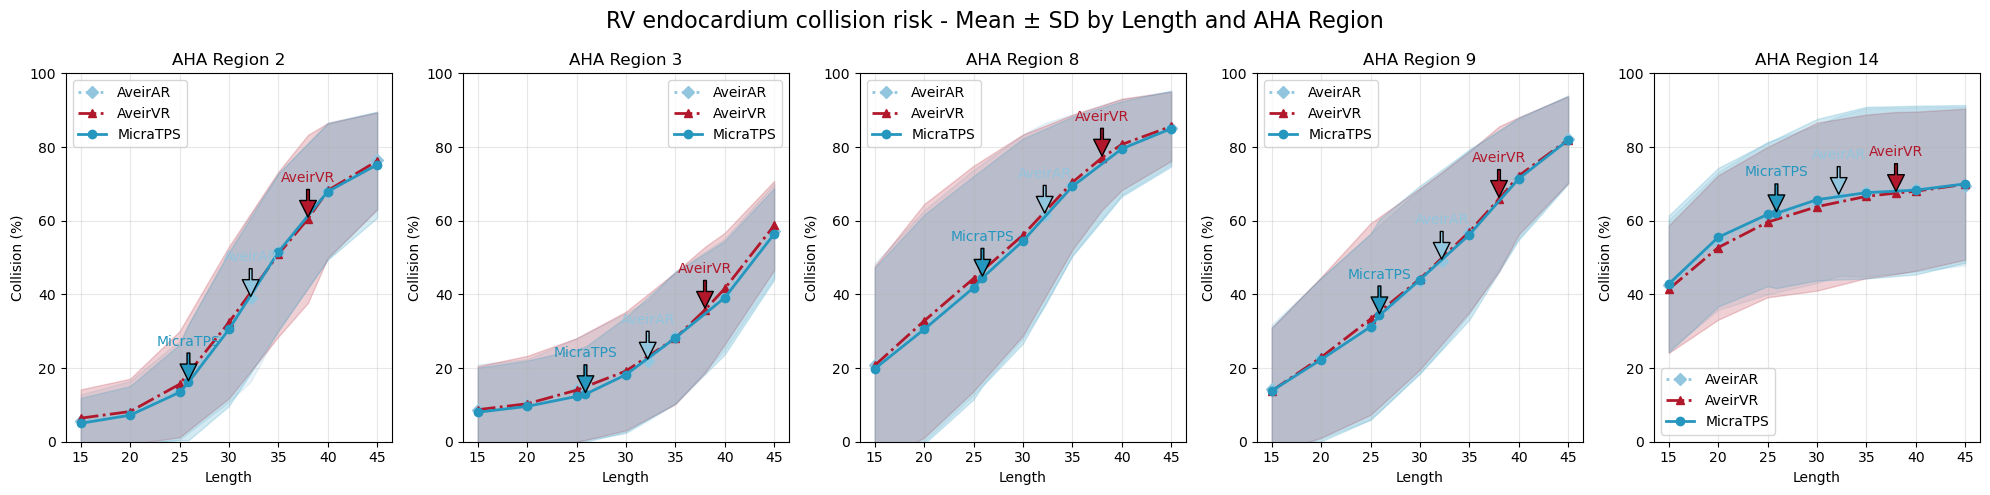

Axes(0.125,0.11;0.133621x0.77)


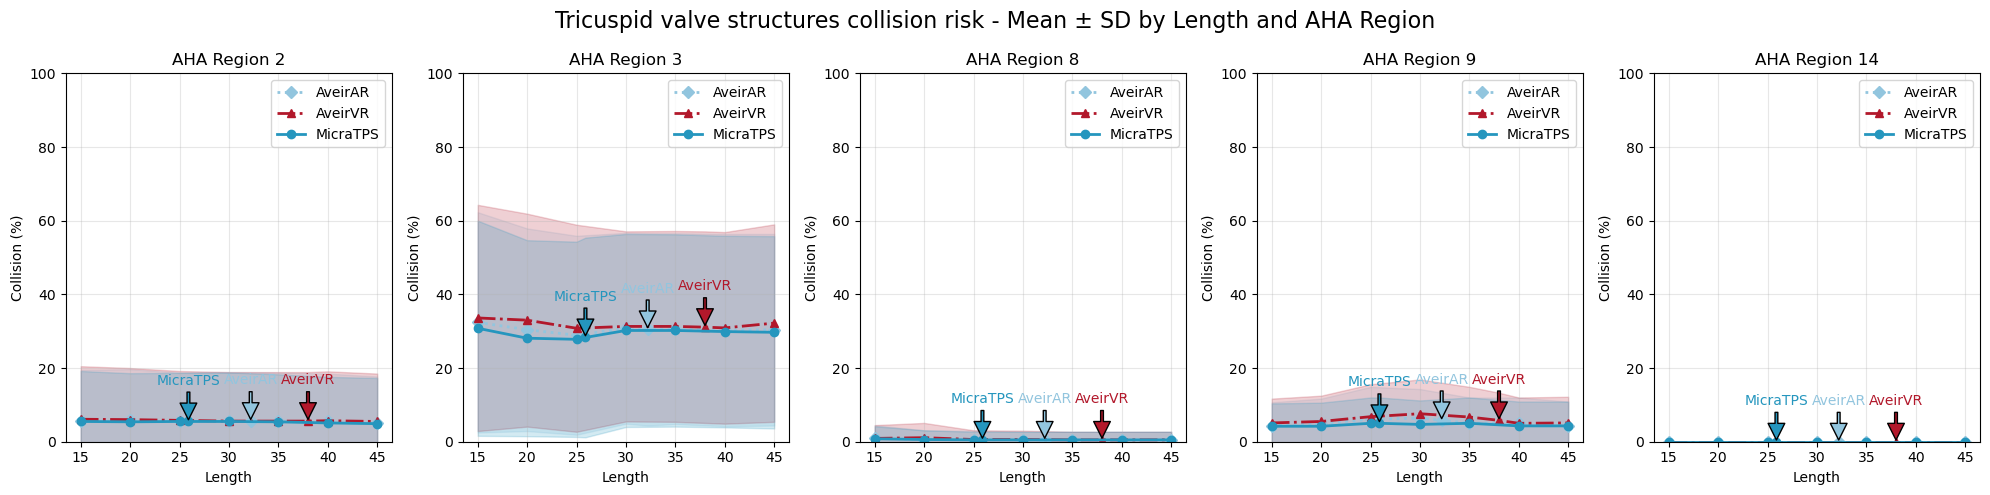


Summary Statistics:


,mean_avg,mean_std,std_avg,std_std
AveirVR_L38_RV_Collision,61.36,13.857215,19.16,3.176539
AveirVR_L38_TV_Collision,8.60,11.512254,9.80,9.314290
AveirVR_L38_PM_Collision,22.20,12.170127,17.32,5.075195
AveirVR_L38_Combined_Collision,72.18,6.005131,15.80,3.235429
AveirVR_L15_RV_Collision,18.20,12.596349,16.18,6.425387
AveirVR_L15_TV_Collision,9.14,12.452245,11.06,10.906438
AveirVR_L15_PM_Collision,20.38,12.236405,15.90,5.968920
AveirVR_L15_Combined_Collision,42.26,13.939670,18.32,3.289620
AveirVR_L20_RV_Collision,25.38,16.310414,19.00,7.842194
AveirVR_L20_TV_Collision,9.12,12.170357,10.78,10.150547


In [3]:
# analysis 

import pandas as pd
import os
import sys
import numpy as np
import matplotlib.pyplot as plt


def read_AHA_csv(merged_df, device, lengths, collision_fields=['Combined_Collision']): 
    main_path = '/data_fast/Work/MS_HF_cohort/images'
    #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
    for length in lengths: #, 15, 20, 25, 30, 35, 40, 45]:  #[22, 27, 32, 37, 42]: 
        for collision_field in collision_fields: #['RV_Collision', 'TV_Collision', 'PM_Collision', 'Combined_Collision']: 
            #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
            if collision_field == 'Combined_Collision':
                images_outpath=f'{main_path}/{device}/'
                add_legend=True
            else: 
                images_outpath=f'{main_path}/{device}/{collision_field}/'
                add_legend=False


            csv_outfile=f'{images_outpath}/sum_plots/RV_septum_polar_sum_{device}_L{length}.csv'
            print(f'CSV outfile: {csv_outfile}')
            df= pd.read_csv(csv_outfile)
            #display(df)

            label= f'{device}_L{length}_{collision_field}'
                # Create formatted column
            df[label] = df.apply(lambda row: f"{row['mean']:.1f} ± {row['std']:.1f}", axis=1)
            # Subset to AHA_region and formatted column
            df = df[["AHA_region", label]]

            # Merge
            if merged_df is None:
                merged_df = df
            else:
                merged_df = pd.merge(merged_df, df, on="AHA_region", how="outer")
    return merged_df


def extract_mean_std_from_formatted(formatted_str):
    """Extract mean and std from formatted string 'mean ± std'"""
    try:
        parts = formatted_str.split(' ± ')
        mean = float(parts[0])
        std = float(parts[1])
        return mean, std
    except:
        return np.nan, np.nan
def plot_collision_data_by_aha(merged_df, output_path=None):
    """
    Plot mean and standard deviation over lengths for each AHA region and collision field
    
    Parameters:
    merged_df: DataFrame with formatted collision data
    output_path: Optional path to save plots
    """
    # Extract device names, lengths, and collision fields from column names
    columns = [col for col in merged_df.columns if col != 'AHA region']
    
    # Parse column names to extract components
    data_info = []
    for col in columns:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length = parts[1].replace('L', '')
            collision_field = '_'.join(parts[2:])
            if device=='Micra': 
                device = 'MicraTPS'

            data_info.append({
                'column': col,
                'device': device,
                'length': float(length),
                'collision_field': collision_field
            })
    
    # Convert to DataFrame for easier manipulation
    info_df = pd.DataFrame(data_info)
    


    # Get unique values
    devices = sorted(info_df['device'].unique())
    collision_fields = sorted(info_df['collision_field'].unique())
    aha_regions = sorted(merged_df['AHA region'].unique())
    
    # Colors for devices
    colors = {'AveirVR': 'red', 'AveirAR': 'blue', 'Micra': 'green'}
    
    # Create plots for each collision field
    for collision_field in collision_fields:
        # First pass: collect all data to determine global y-axis limits
        all_means = []
        all_stds = []
        
        for aha_region in aha_regions:
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()
                
                for col in device_cols:
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            all_means.append(mean)
                            all_stds.append(std)
        
        # Calculate global y-axis limits
        if all_means and all_stds:
            all_means = np.array(all_means)
            all_stds = np.array(all_stds)
            y_min = np.min(all_means - all_stds)
            y_max = np.max(all_means + all_stds)
            # Add some padding
            y_range = y_max - y_min
            y_min = max(0, y_min - 0.05 * y_range)  # Don't go below 0
            y_max = y_max + 0.05 * y_range
        else:
            y_min, y_max = 0, 100  # Default range
        
        n_regions = len(aha_regions)
        n_rows = 1  # Single row
        n_cols = n_regions  # One column per AHA region
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 5))
        # Handle different subplot configurations
        if n_regions == 1:
            # Single subplot case
            axes = [axes]
        else:
            # Multiple subplots case
            if isinstance(axes, np.ndarray):
                if axes.ndim == 1:
                    # Single row or single column of subplots
                    axes = axes.tolist()
                else:
                    # Multiple rows and columns
                    axes = axes.flatten().tolist()
            else:
                # This shouldn't happen with n_regions > 1, but just in case
                axes = [axes]

        if collision_field == 'Combined_Collision': 
            title_str='Combined collision risk'
        elif collision_field == 'RV_Collision': 
            title_str='RV endocardium collision risk'
        elif collision_field == 'TV_Collision': 
            title_str='Tricuspid valve structures collision risk'
        elif collision_field == 'PM_Collision': 
            title_str = 'Papillary muscles and moderator band collision risk'
        else: 
            title_str=collision_field

        fig.suptitle(f'{title_str} - Mean ± SD by Length and AHA Region', fontsize=16, y=0.98)
        print(axes[0])
        for i, aha_region in enumerate(aha_regions):
            ax = axes[i] if n_regions > 1 else axes[0]
            
            # Get data for this AHA region
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                # Filter columns for this device and collision field
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()
                
                if not device_cols:
                    continue
                
                # Extract lengths and values
                lengths = []
                means = []
                stds = []
                
                for col in device_cols:
                    # Get length from column name
                    length = info_df[info_df['column'] == col]['length'].iloc[0]
                    
                    # Get formatted value
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            lengths.append(length)
                            means.append(mean)
                            stds.append(std)
                
                if lengths:  # Only plot if we have data
                    lengths = np.array(lengths)
                    means = np.array(means)
                    stds = np.array(stds)
                    
                    # Sort by length
                    sort_idx = np.argsort(lengths)
                    lengths = lengths[sort_idx]
                    means = means[sort_idx]
                    stds = stds[sort_idx]
                    
                    # Plot mean line with error bars
                    color = colors.get(device, 'black')
                    #ax.plot(lengths, means, marker='o', color=color, label=device, linewidth=2)
                    device_colors = {
                        'Micra': '#2596be',
                        'MicraTPS': '#2596be',
                        'OtherPallete': '#f4a582', 
                        'AveirVR': '#b2182b',
                        'AveirAR': '#92c5de'
                    }
                    device_linestyles = {
                        'Micra': '-',
                        'MicraTPS': '-',
                        'OtherPallete': '--',
                        'AveirVR': '-.',
                        'AveirAR': ':'
                    }
                    device_markers = {
                        'Micra': 'o',
                        'MicraTPS': 'o',
                        'OtherPallete': 's',
                        'AveirVR': '^',
                        'AveirAR': 'D'
                    }
                    init_lens = {
                        'AveirVR': 38,
                        'AveirAR': 32.2,
                        'MicraTPS': 25.9  # If you use MicraTPS as a device name
                    }

                    ax.plot(lengths, means, label=device, linewidth=2, 
                            color=device_colors.get(device, '#000000'), 
                            linestyle=device_linestyles.get(device, '-'),
                            marker=device_markers.get(device, 'o'))
                    ax.fill_between(lengths, means - stds, means + stds, 
                                    color=device_colors.get(device, '#000000'), alpha=0.2) 
                                  #color=color, alpha=0.2)
                    # Add arrow at init_len
                    init_len = init_lens.get(device)
                    if init_len is not None and init_len in lengths:
                        idx = np.where(lengths == init_len)[0]
                        if len(idx) > 0:
                            y_val = means[idx[0]]
                            ax.annotate(
                                device,
                                xy=(init_len, y_val),
                                xytext=(init_len, y_val + 10),  # Adjust offset as needed
                                arrowprops=dict(facecolor=device_colors.get(device, '#000000'), shrink=0.05, width=2),
                                ha='center', color=device_colors.get(device, '#000000'), fontsize=10
                            )
            ax.set_title(f'AHA Region {aha_region}')
            ax.set_xlabel('Length')
            ax.set_ylabel('Collision (%)')
            ax.grid(True, alpha=0.3)
            ax.legend()
            
            # Set the same y-axis limits for all subplots
            ax.set_ylim(0, 100)
        
        # Hide empty subplots
        for i in range(n_regions, len(axes)):
            axes[i].set_visible(False)
        
        plt.tight_layout()
        
        # Save plot if output path provided
        if output_path:
            os.makedirs(output_path, exist_ok=True)
            plt.savefig(f'{output_path}/{collision_field}_by_AHA_region.png', 
                       dpi=300, bbox_inches='tight')
        
        plt.show()

def create_summary_table(merged_df, output_path=None):
    """Create summary statistics table"""
    # Extract numeric data from formatted strings
    numeric_data = {}
    
    for col in merged_df.columns:
        if col != 'AHA region':
            means = []
            stds = []
            for val in merged_df[col]:
                if pd.notna(val):
                    mean, std = extract_mean_std_from_formatted(val)
                    means.append(mean)
                    stds.append(std)
            
            numeric_data[col] = {
                'mean_avg': np.nanmean(means),
                'mean_std': np.nanstd(means),
                'std_avg': np.nanmean(stds),
                'std_std': np.nanstd(stds)
            }
    
    summary_df = pd.DataFrame(numeric_data).T
    
    if output_path:
        summary_df.to_csv(f'{output_path}/summary_statistics.csv')
    
    return summary_df

if __name__ == "__main__":
    # Initialize empty merged DataFrame
    merged_df = None

    for device in ['AveirVR', 'AveirAR', 'Micra']: #['Micra']: 
        if device == 'AveirVR':
            init_len= 38
        elif device == 'AveirAR': 
            init_len= 32.2
        elif device == 'Micra': 
            init_len = 25.9
        else: 
            print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')        

        lengths=[init_len, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
        coll_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']
        merged_df=read_AHA_csv(merged_df, device, lengths, collision_fields=coll_fields)

    # Rename for output
    merged_df.rename(columns={"AHA_region": "AHA region"}, inplace=True)

    # Sort by AHA region
    merged_df.sort_values("AHA region", inplace=True)
    #display(merged_df)
    #merged_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=False)
    #pivot_df = merged_df.set_index("AHA region").T
    #pd.set_option('display.max_rows', None)  # Show all rows in DataFrame display

    #display(pivot_df)
    #pivot_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=True)
    ###################################################################################
    # Rename for output
    merged_df.rename(columns={"AHA_region": "AHA region"}, inplace=True)
    
    # Sort by AHA region
    merged_df.sort_values("AHA region", inplace=True)
    
    #display(merged_df)
    #merged_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=False)
    
    pivot_df = merged_df.set_index("AHA region").T
    pd.set_option('display.max_rows', None) # Show all rows in DataFrame display
    #display(pivot_df)
    pivot_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=True)
    
    # NEW: Create plots for collision data
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/plots'
    plot_collision_data_by_aha(merged_df, output_path=output_plot_path)
    
    # NEW: Create summary statistics
    summary_stats = create_summary_table(merged_df, output_path=output_plot_path)
    print("\nSummary Statistics:")
    display(summary_stats)


In [16]:
import pandas as pd
import numpy as np

mainpath='/data_fast/Work/MS_HF_cohort/images/'

for device in ['AveirVR', 'AveirAR', 'Micra']: # #
    if device == 'AveirVR':
        init_len= 38
    elif device == 'AveirAR': 
        init_len= 32.2
    elif device == 'Micra': 
        init_len = 25.9
    else: 
        print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')

    lengths=[init_len] #, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
    for length in lengths:
        all_collision_values = []
        for AHA_region in [2,3,8,9,14]: 
            csv_file=f'{mainpath}/{device}/csv/{AHA_region}_L{length}.csv'
            print(f'CSV file: {csv_file}')  
            df = pd.read_csv(csv_file)            
            print(f'AHA region {AHA_region}: MEAN: {np.mean(df['collision_value']*10):1.1f}%, STD: {10*np.std(df['collision_value']):1.1f}%')
            all_collision_values.extend(df['collision_value'].tolist())

        print(f'All collision values for {device} at length {length}: {np.mean(all_collision_values)*10:1.1f}%, STD: {10*np.std(all_collision_values):1.1f}%')  




CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/2_L38.csv
AHA region 2: MEAN: 67.1%, STD: 17.6%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/3_L38.csv
AHA region 3: MEAN: 66.5%, STD: 14.7%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/8_L38.csv
AHA region 8: MEAN: 79.6%, STD: 13.0%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/9_L38.csv
AHA region 9: MEAN: 79.4%, STD: 12.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/14_L38.csv
AHA region 14: MEAN: 68.3%, STD: 21.2%
All collision values for AveirVR at length 38: 71.9%, STD: 17.6%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/2_L32.2.csv
AHA region 2: MEAN: 47.1%, STD: 19.1%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/3_L32.2.csv
AHA region 3: MEAN: 57.6%, STD: 16.8%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/8_L32.2.csv
AHA region 8: MEAN: 70.8%, STD: 19.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/9_L32.2.csv


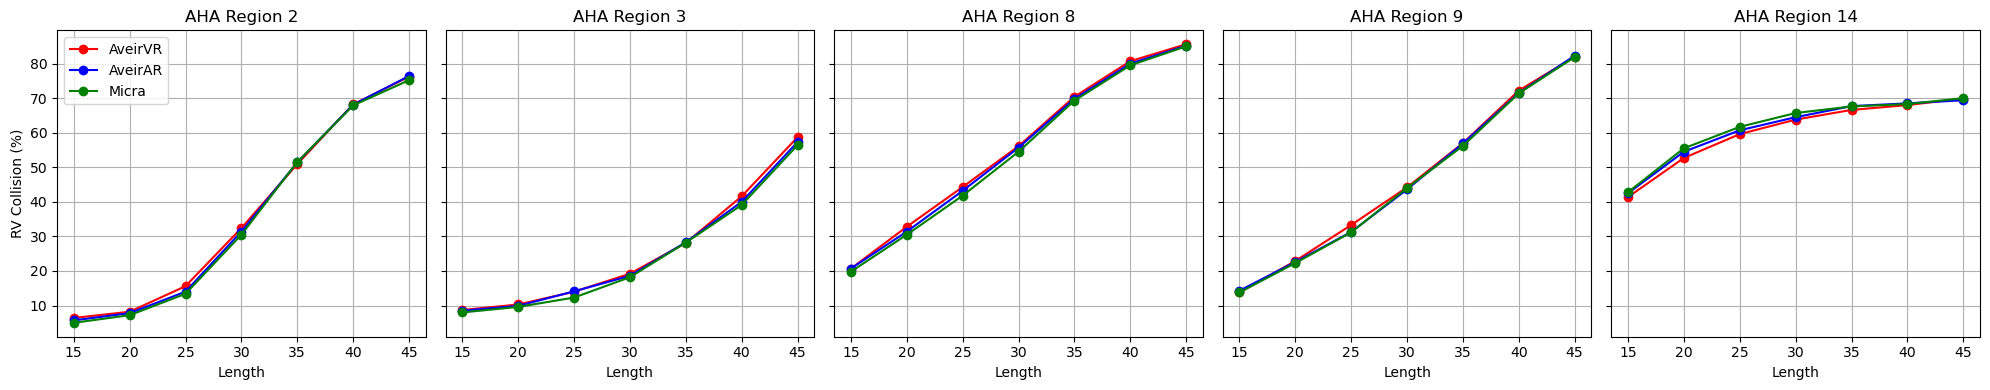

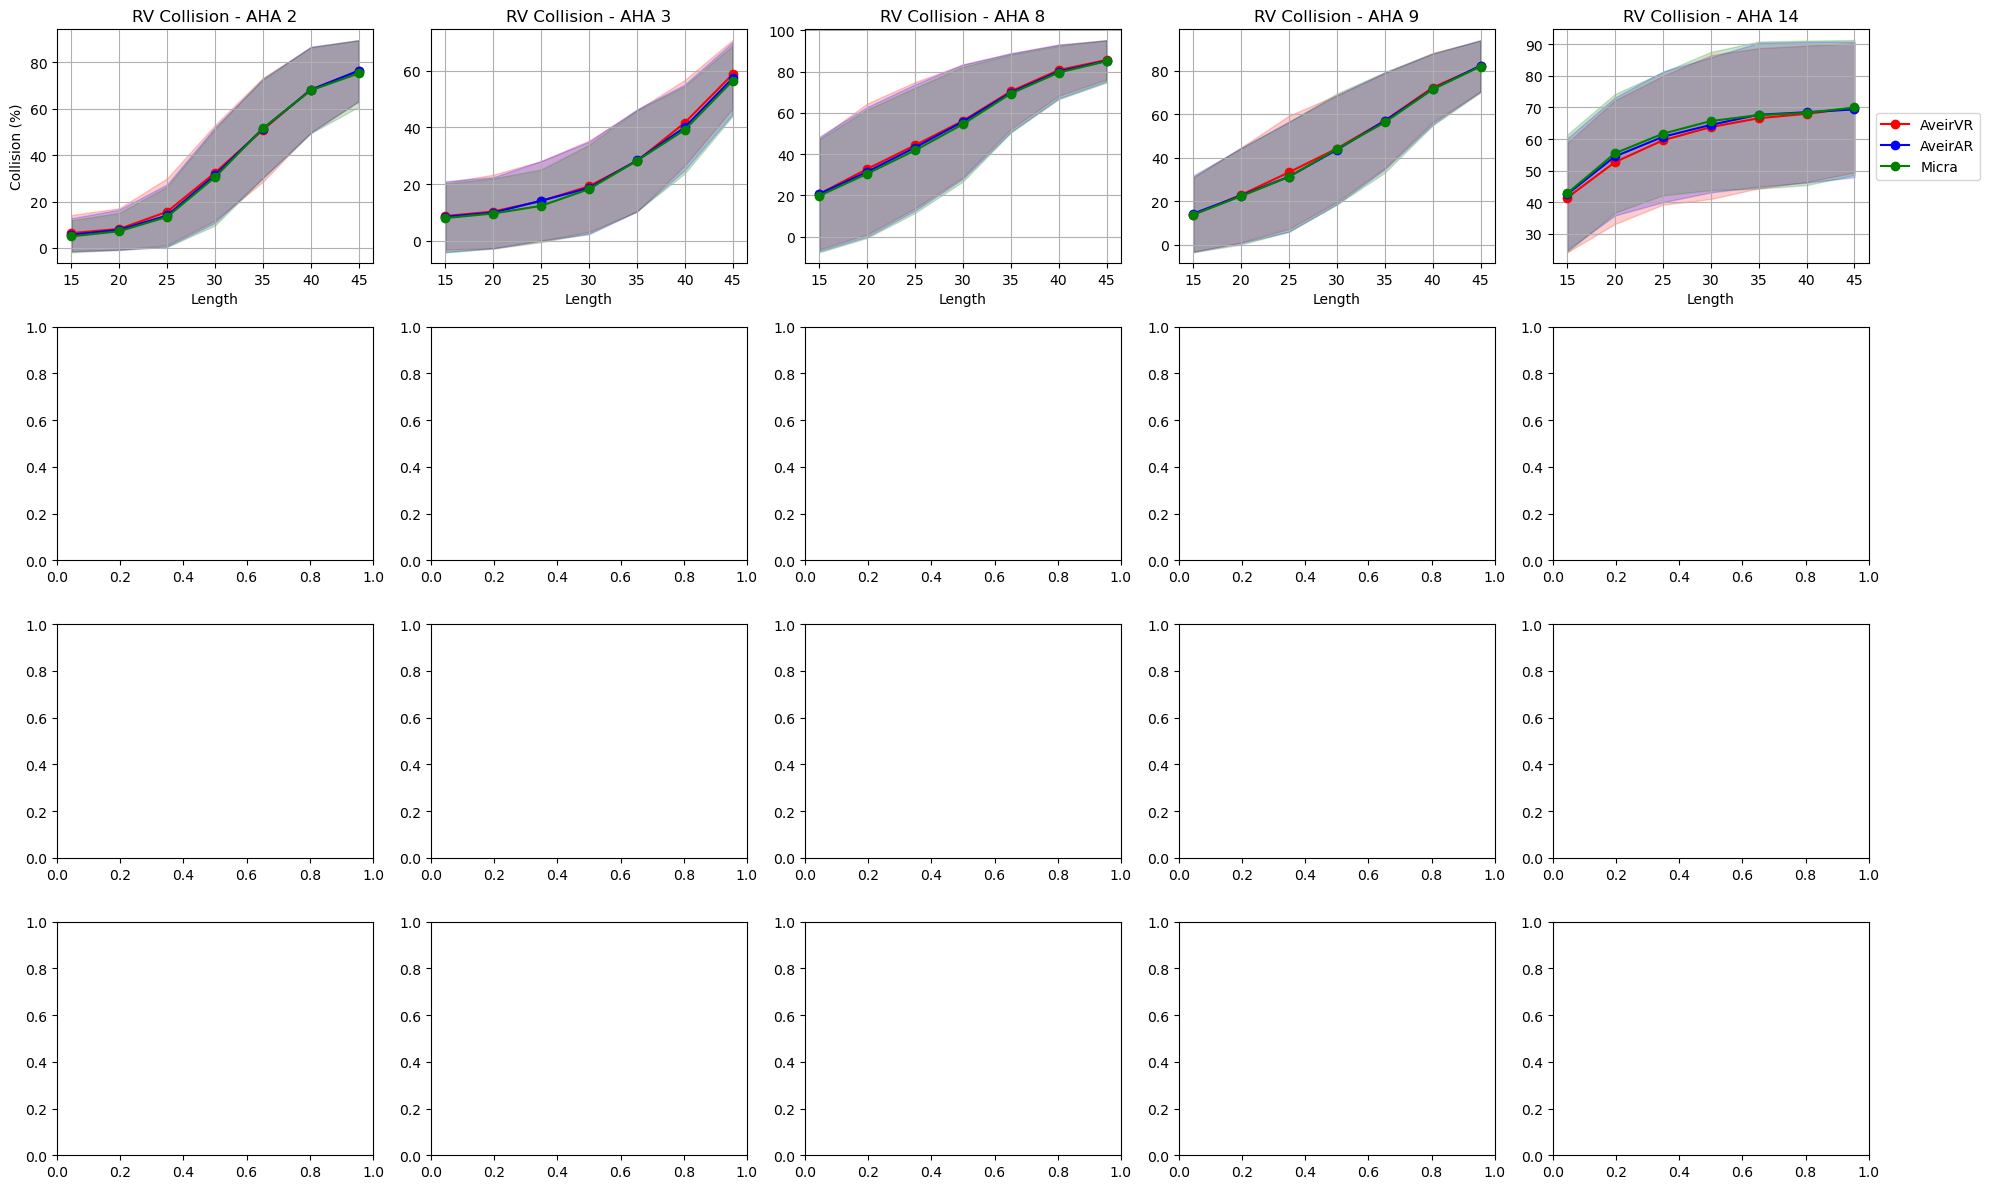

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# Lengths
lengths = np.array([15, 20, 25, 30, 35, 40, 45])

# Data format: data[metric][region][device] = (means, stds)
data = {
    "RV Collision": {
        2: {
            'AveirVR': ([6.4, 8.2, 15.6, 32.4, 50.9, 68.2, 76.2], [7.8, 8.9, 14.4, 20.6, 22.4, 18.3, 13.2]),
            'AveirAR': ([5.7, 7.8, 14.0, 31.4, 51.4, 68.1, 76.4], [7.1, 8.7, 13.4, 20.6, 21.2, 18.6, 13.1]),
            'Micra':   ([5.0, 7.2, 13.4, 30.5, 51.5, 67.9, 75.2], [6.9, 7.9, 13.0, 20.8, 21.4, 18.5, 14.4])
        },
        3: {
            'AveirVR': ([8.7, 10.3, 14.0, 19.2, 28.1, 41.6, 58.7], [11.8, 13.0, 14.1, 16.1, 17.9, 15.1, 12.1]),
            'AveirAR': ([8.5, 9.9, 14.1, 18.6, 28.3, 40.0, 57.3], [12.5, 12.5, 14.0, 16.3, 18.0, 15.1, 12.7]),
            'Micra':   ([8.0, 9.6, 12.3, 18.2, 28.2, 39.1, 56.4], [12.1, 12.4, 12.8, 15.6, 17.8, 15.4, 12.4])
        },
        8: {
            'AveirVR': ([20.7, 32.8, 44.3, 56.1, 70.4, 80.7, 85.6], [26.9, 31.7, 30.6, 27.3, 18.3, 12.4, 9.4]),
            'AveirAR': ([20.7, 31.4, 43.2, 55.7, 69.8, 80.0, 85.2], [27.7, 31.4, 30.6, 27.7, 19.1, 13.0, 10.0]),
            'Micra':   ([19.8, 30.5, 41.8, 54.5, 69.3, 79.5, 85.0], [27.4, 31.1, 30.3, 27.8, 18.9, 12.9, 10.3])
        },
        9: {
            'AveirVR': ([13.8, 22.9, 33.3, 44.2, 57.0, 72.2, 82.0], [17.1, 21.8, 26.0, 24.6, 21.8, 15.9, 11.8]),
            'AveirAR': ([14.3, 22.6, 31.3, 43.6, 56.9, 71.5, 82.3], [17.5, 21.8, 25.3, 25.0, 22.3, 16.2, 11.8]),
            'Micra':   ([13.8, 22.3, 31.2, 44.0, 56.2, 71.4, 81.9], [17.3, 22.2, 25.2, 25.5, 23.1, 16.6, 11.9])
        },
        14: {
            'AveirVR': ([41.4, 52.7, 59.6, 63.8, 66.6, 68.0, 69.9], [17.3, 19.6, 20.4, 22.8, 22.2, 21.6, 20.5]),
            'AveirAR': ([42.5, 54.5, 60.7, 64.5, 67.7, 68.5, 69.4], [17.7, 18.7, 20.7, 21.4, 22.8, 22.3, 21.5]),
            'Micra':   ([42.8, 55.5, 61.7, 65.7, 67.6, 68.3, 70.0], [18.6, 18.8, 19.5, 21.9, 23.3, 22.9, 21.4])
        }
    },
    "TV Collision": {
        # Fill in the same way with your TV collision table
    },
    "PM Collision": {
        # Fill in with PM collision table
    },
    "Combined Collision": {
        # Fill in with combined collision table
    }
}

colors = {'AveirVR': 'red', 'AveirAR': 'blue', 'Micra': 'green'}

# Plot
n_metrics = len(data)
n_regions = len(next(iter(data.values())))
fig, axes = plt.subplots(n_metrics, n_regions, figsize=(4 * n_regions, 3 * n_metrics), sharey=False)

for row_idx, (metric, regions) in enumerate(data.items()):
    for col_idx, (region, devices) in enumerate(regions.items()):
        ax = axes[row_idx, col_idx] if n_metrics > 1 else axes[col_idx]
        for device, (means, stds) in devices.items():
            means = np.array(means)
            stds = np.array(stds)
            ax.plot(lengths, means, marker='o', color=colors[device], label=device)
            ax.fill_between(lengths, means - stds, means + stds, color=colors[device], alpha=0.2)
        ax.set_title(f"{metric} - AHA {region}")
        ax.set_xlabel("Length")
        ax.grid(True)
        if col_idx == 0:
            ax.set_ylabel("Collision (%)")
        if row_idx == 0 and col_idx == n_regions - 1:
            ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.tight_layout()
plt.show()